# NIST TN 1822 — Verif.5.2: Maximum flow rates

100 agents in an 8 m x 5 m room with a 1 m exit. NIST §3.1.5 sets a predefined maximum flow of 1.33 p/m/s (IMO MSC/Circ.1238 reference). The CollisionFreeSpeedModel has no door-flow limit of its own, so this is the restricted-flow reading: the run enables the jupedsim-scenarios exit throughput limiter at 1.33 p/s and checks that the measured flow stays at or below it. The emergent flow without the limiter is shown for comparison.

In [1]:
from datetime import datetime
print(f"Executed on {datetime.now().astimezone().strftime('%d %B %Y, %H:%M %Z')}")

Executed on 15 October 2026, 17:28 CEST


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pedpy
from shapely.geometry import Point, Polygon

from jupedsim_scenarios import load_scenario, run_scenario

In [3]:
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#f7f7f5",
    "axes.edgecolor": "#3a3a3a",
    "axes.labelcolor": "#1d1d1d",
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "figure.figsize": (8, 5),
})

In [4]:
import numpy as np

# House style for the V&V figures (plain matplotlib; applied per figure via rc_context).
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, PathPatch
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.path import Path as MplPath

VV_BLUE, VV_ORANGE, VV_RED, VV_GREEN = "#0072B2", "#E69F00", "#D55E00", "#009E73"
VV_RC = {
    "figure.facecolor": "white", "axes.facecolor": "white", "figure.dpi": 150,
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "lightgrey", "axes.labelcolor": "dimgrey",
    "axes.titlecolor": "#333333", "axes.titleweight": "normal", "axes.titlesize": 11,
    "axes.spines.left": False, "axes.spines.bottom": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": "dimgrey", "ytick.color": "dimgrey",
    "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": True, "legend.facecolor": "white", "legend.framealpha": 0.8,
    "legend.edgecolor": "lightgrey", "legend.labelcolor": "dimgrey", "legend.fontsize": 9,
}


def vv_polygon_patch(geom, **kwargs):
    """Matplotlib patch for a shapely (Multi)Polygon, holes included."""
    verts, codes = [], []
    for part in getattr(geom, "geoms", [geom]):
        for ring in [part.exterior, *part.interiors]:
            xy = np.asarray(ring.coords)
            verts.extend(xy)
            codes += [MplPath.MOVETO] + [MplPath.LINETO] * (len(xy) - 2) + [MplPath.CLOSEPOLY]
    return PathPatch(MplPath(verts, codes), **kwargs)


def vv_draw_scenario(ax, scenario, starts=True, pad=0.04):
    """Draw walkable area, exits and start areas of a loaded scenario; return legend handles."""
    ax.add_patch(vv_polygon_patch(scenario.walkable_polygon, facecolor="#eeeeee",
                                  edgecolor="dimgrey", linewidth=1.4, zorder=1))
    handles = [Patch(facecolor="#eeeeee", edgecolor="dimgrey", label="walkable area")]
    if starts:
        for dist in scenario.distributions.values():
            ax.add_patch(MplPolygon(dist["coordinates"], closed=True,
                                    facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                                    linestyle="--", linewidth=1.2, hatch="..", zorder=2))
        handles.append(Patch(facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                             linestyle="--", hatch="..", label="start area"))
    for ex in scenario.exits.values():
        ax.add_patch(MplPolygon(ex["coordinates"], closed=True,
                                facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                                linewidth=1.2, hatch="///", zorder=3))
    if scenario.exits:
        handles.append(Patch(facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                             hatch="///", label="exit"))
    minx, miny, maxx, maxy = scenario.walkable_polygon.bounds
    m = pad * max(maxx - minx, maxy - miny)
    ax.set_xlim(minx - m, maxx + m)
    ax.set_ylim(miny - m, maxy + m)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    return handles


def vv_agent_count(scenario):
    """Total number of agents placed by the scenario's start areas."""
    return sum(int(d.get("parameters", {}).get("number", 0)) for d in scenario.distributions.values())

## Load and run

In [5]:
SCENARIO_ZIP = Path("scenario_files") / "Nist-5-2-max-flow.zip"
CAP_PMS = 1.33  # p/m/s; equals the limiter's max_throughput (p/s) for a 1 m exit
EXIT_WIDTH_M = 1.0
CAP_TOLERANCE = 0.01  # relative; see the acceptance cell


def run(limiter_on):
    scenario = load_scenario(str(SCENARIO_ZIP))
    for exit_ in scenario.raw["exits"].values():
        exit_["enable_throughput_throttling"] = limiter_on
        exit_["max_throughput"] = CAP_PMS
    result = run_scenario(scenario, seed=42)
    return scenario, result, result.trajectory_dataframe()


runs = {"limiter off": run(False), "limiter on": run(True)}
scenario, result, df = runs["limiter on"]
print(scenario.summary())

Scenario: scenario_files/Nist-5-2-max-flow.zip
  Model:         CollisionFreeSpeedModel
  Seed:          42
  Max time:      240s
  Exits:         1
  Distributions: 1
  Stages:        0
  Zones:         0
  Journeys:      1
  Agents:        ~100
  Journey elems: 2
  Route:         1 distribution, 0 checkpoint, 1 exit
  Sequence:      jps-distributions_0 -> jps-exits_0
    jps-distributions_0: 100 agents


## Scenario figure

Room geometry from the loaded scenario.

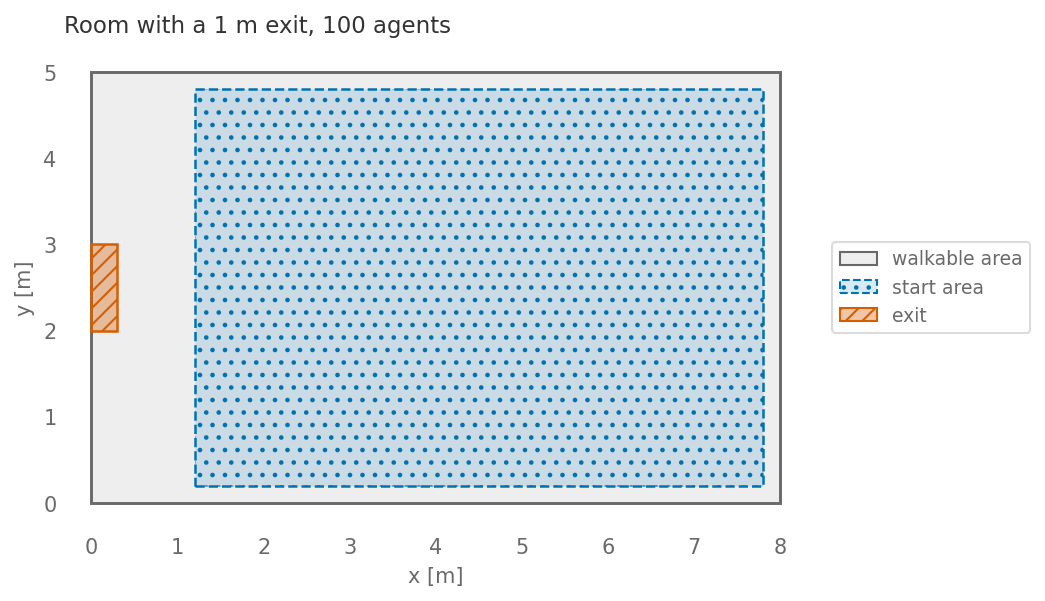

In [6]:
# Scenario geometry from the loaded ZIP.
with plt.rc_context(VV_RC):
    fig, ax = plt.subplots(figsize=(6.4, 4.4))
    handles = vv_draw_scenario(ax, scenario)
    ax.set_title(f"Room with a 1 m exit, {vv_agent_count(scenario)} agents", loc="left")
    ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.02, 0.5))
    plt.show()

## Exit times and specific flow

An agent is removed when the exit stage accepts it, and the limiter delays that removal while the agent waits inside the exit polygon. The exit time is therefore the agent's last trajectory frame, not its first crossing of the exit line.

Specific flow = (N - 1) / (t_last - t_first) / exit width, over the N exit times (N - 1 intervals).

In [7]:
exit_times = {}
for name, (_, res, tdf_) in runs.items():
    exit_times[name] = np.sort((tdf_.groupby("id").frame.max() / res.frame_rate).values)


def specific_flow(times):
    return (len(times) - 1) / (times[-1] - times[0]) / EXIT_WIDTH_M


flows = {name: specific_flow(t) for name, t in exit_times.items()}
for name, t in exit_times.items():
    print(f"{name:12s}: N = {len(t)}, first exit {t[0]:.1f} s, last exit {t[-1]:.1f} s, "
          f"specific flow = {flows[name]:.3f} p/m/s")

limiter off : N = 100, first exit 0.7 s, last exit 19.6 s, specific flow = 5.238 p/m/s
limiter on  : N = 100, first exit 0.7 s, last exit 76.0 s, specific flow = 1.315 p/m/s


## Cumulative exits

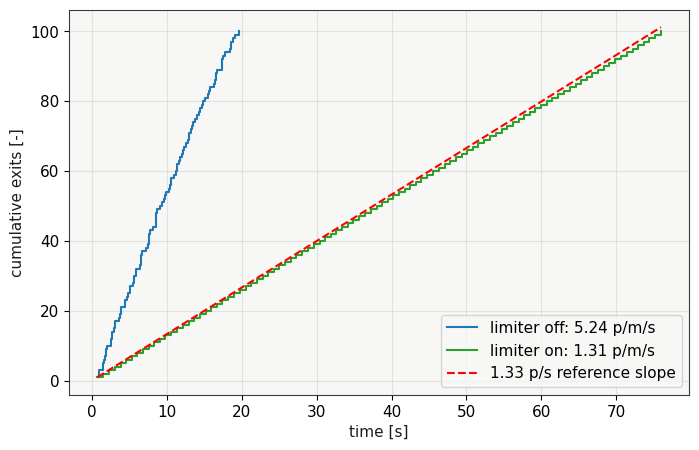

In [8]:
fig, ax = plt.subplots()
colors = {"limiter off": "tab:blue", "limiter on": "tab:green"}
for name, t in exit_times.items():
    ax.step(t, np.arange(1, len(t) + 1), where="post", color=colors[name],
            label=f"{name}: {flows[name]:.2f} p/m/s")
t_on = exit_times["limiter on"]
ref_t = np.array([t_on[0], t_on[-1]])
ax.plot(ref_t, 1 + CAP_PMS * EXIT_WIDTH_M * (ref_t - t_on[0]), "r--",
        label=f"{CAP_PMS} p/s reference slope")
ax.set_xlabel("time [s]"); ax.set_ylabel("cumulative exits [-]"); ax.legend()
plt.show()

## Acceptance (restricted-flow reading, maintainer decision D12)

NIST Verif.5.2 requires that the exit flow does not exceed the predefined maximum of 1.33 p/m/s (1.33 p/s for this 1 m exit). The run enables the jupedsim-scenarios exit throughput limiter (`enable_throughput_throttling = True`, `max_throughput = 1.33` p/s) and asserts that the measured specific flow stays at or below the cap, with a relative tolerance of 1 %. The tolerance covers the 0.1 s sampling of the trajectory file against an egress span of about 75 s (under 0.3 %); the limiter's tick discretisation only lowers the flow.

The emergent flow with the limiter off is reported for information only and is not asserted.

In [9]:
cap = CAP_PMS * (1 + CAP_TOLERANCE)
print(f"limiter on : {flows['limiter on']:.3f} p/m/s (cap {CAP_PMS}, with tolerance {cap:.4f})")
print(f"limiter off: {flows['limiter off']:.3f} p/m/s (emergent, information only)")
for name, (_, res, _) in runs.items():
    print(f"{name}: evacuation time = {res.evacuation_time:.1f} s; agents remaining = {res.agents_remaining}")
    assert res.agents_remaining == 0, (name, res.agents_remaining)
assert flows["limiter on"] <= cap, flows["limiter on"]
for _, res, _ in runs.values():
    res.cleanup()

limiter on : 1.315 p/m/s (cap 1.33, with tolerance 1.3433)
limiter off: 5.238 p/m/s (emergent, information only)
limiter off: evacuation time = 19.7 s; agents remaining = 0
limiter on: evacuation time = 76.0 s; agents remaining = 0
